# 2. Change detection by segmentation and comparison

The most direct way to find new buildings is to find all of them in both steps, then compare the predictions. To this end, we will need a building segmentor.

TorchGeo does not have a trained version, but it has models and datasets to train one (and while making this tutorial I really think I should probs some pretrained one for this). [LandCover.ai](https://landcover.ai.linuxpolska.com/) has aerial orthophotos of Poland with five classes: background, building, woodland,
water and road. I trained a U-Net on it before the workshop, so we will use that here for a small finetuning step on our dataset.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from lightning import Trainer
from lightning.pytorch.callbacks import TQDMProgressBar
from matplotlib.colors import ListedColormap
from shapely.geometry import box
from torch.utils.data import DataLoader
from torchmetrics.classification import BinaryF1Score, BinaryJaccardIndex

from torchgeo.datasets import RasterDataset, VectorDataset
from torchgeo.samplers import GriddedPatchSampler, RandomPatchSampler
from torchgeo.tasks import SemanticSegmentation

PREPARED = Path('../data/prepared')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

train_roi = box(457250, 100000, 458250, 103000)
test_roi = box(458250, 100000, 458750, 103000)
val_roi = box(458750, 100000, 459500, 103000)

/opt/homebrew/Caskroom/miniforge/base/envs/tgeo/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/homebrew/Caskroom/miniforge/base/envs/tgeo/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## Data

We use the data we prepared before. The model expects the images to be normalised to interval [0, 1] so we will also add a small tranform to handle this. These transforms can in general be quite diverse and I really urge you to think about this when doing your own things as these are really important. In first case, if model expect certain range we MUST match our data to that (simple standardisation is usually what we do). On the other hand, things like flips, rotations, crops serve as "data expansion", virtutally expanding the dataset on the fly. We will use Kornia library, as this is what TorchGeo uses, and these transforms also work on GPU and operate on batched data so they are fast!

We will also use a pre-prepared change mask instaed of stacking togehter atasets but that remains a valid option for your usecases.

In [2]:
import kornia.augmentation as K

# sequential as we have 2 images. The operation is (x - mean) / std, so to get int8 images to 0,1, we just set std=255 and voila we have [0,1] range.
normalize = K.AugmentationSequential(K.Normalize(mean=0, std=255), data_keys=None, keepdim=True)

class Mask(RasterDataset):
    is_image = False


before = RasterDataset(PREPARED / 'rgb/2018.tif', transforms=normalize)
after = RasterDataset(PREPARED / 'rgb/2024.tif', transforms=normalize)
change = Mask(PREPARED / 'labels/change.tif')
# combine, like before
pair = before & after & change

# A land-cover model

In intro we've seen how a regular training and inference loop looks like in basic Torch. TorchGeo is based on Torch Lightning, so it simplifies our life a bit, but still enables all the tinkering.

So to train and use a semantic segmentation model (which assigns a land cover class to each pixel) we use a `SematnicSegmentation` task. It combines model, loss, metrics and optimisation into a neat little block. Here I'd also point out that this is very useful for collaboration as it enables easy testing if stuff works).

I trained the UNet within the SemSeg taaks on LandCover.ai datasets beforehand, as it takes some time. Later we will just adjust it slightly for our data but let's first see how it works.

Text(0.5, 1.0, 'red: building, green: woodland, blue: water, black: road')

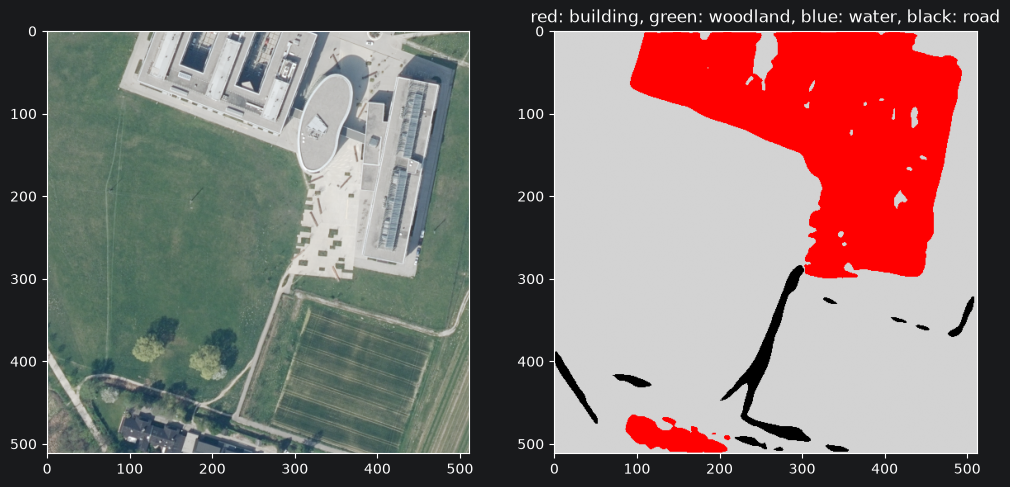

In [3]:
# from torchgeo.models import ResNet50_Weights
# landcover = SemanticSegmentation(
#     model='unet', backbone='resnet50', weights=ResNet50_Weights.FMOW_RGB_GASSL, num_classes=5
# )
landcover = SemanticSegmentation.load_from_checkpoint('../checkpoints/ckpt_landcover.ckpt')
landcover = landcover.to(DEVICE).eval()

CLASSES = ListedColormap(['lightgrey', 'red', 'green', 'blue', 'black'])  # background, building, woodland, water, road


def predict(model, image):
    """Classify pixels in image"""
    with torch.no_grad():
        return model(image.to(DEVICE)).argmax(dim=1).cpu()
        # return model(image.to(DEVICE))[:, 1].cpu()


image = after[458700:458956, 101100:101356]['image']
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image.permute(1, 2, 0))
axes[1].imshow(predict(landcover, image[None])[0], cmap=CLASSES, vmin=0, vmax=4)
axes[1].set_title('red: building, green: woodland, blue: water, black: road')

## Buildings in both years

We only want the building class (1). And we now apply this to our data where we know there are some new houses.

torch.Size([256, 256])


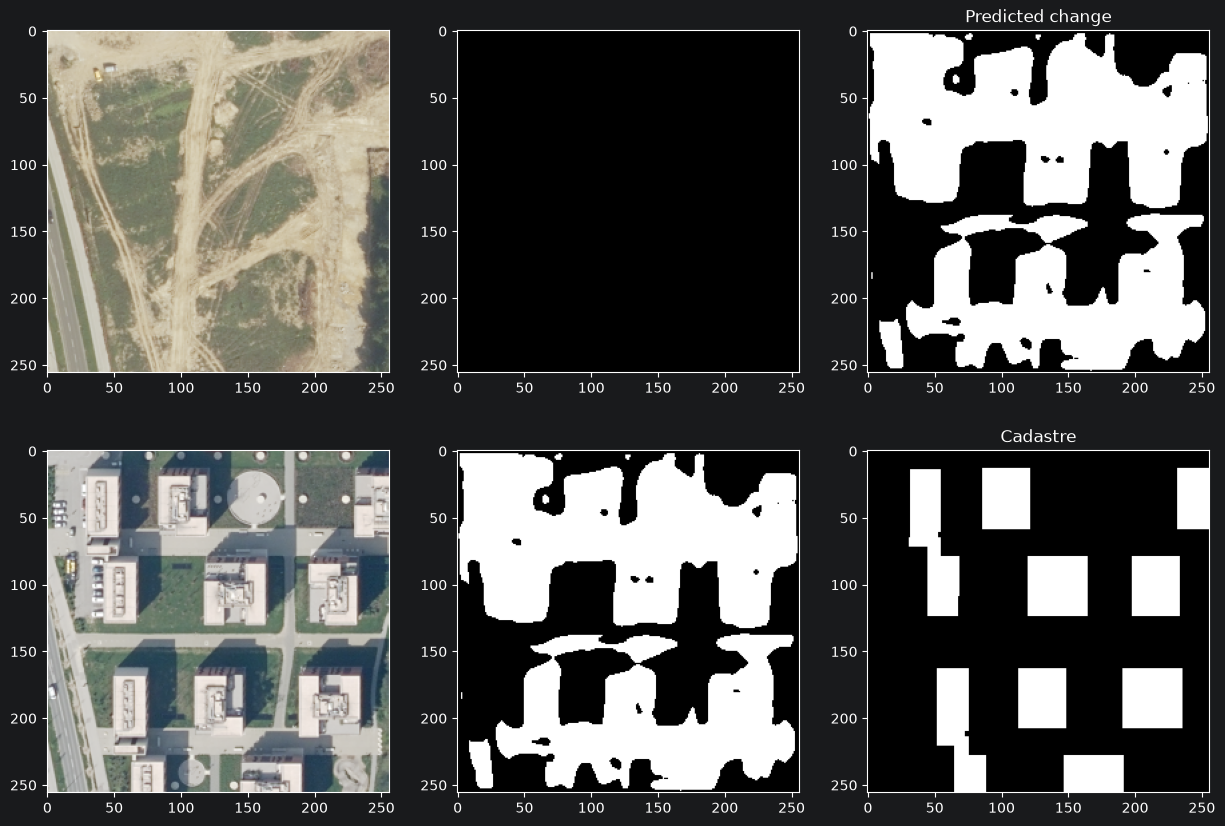

In [12]:
def buildings(model, image):
    """Get only classified buidlings in image"""
    with torch.no_grad():
        return predict(model, image) == 1


def show_change(model, x0, y0, size=128):
    sample = pair[x0 : x0 + size, y0 : y0 + size]
    image = sample['image'][None]
    buildings_before = buildings(model, image[:, :3])[0]
    buildings_after = buildings(model, image[:, 3:])[0]

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes[0, 0].imshow(image[0, :3].permute(1, 2, 0))
    axes[0, 1].imshow(buildings_before, cmap='gray')
    axes[1, 0].imshow(image[0, 3:].permute(1, 2, 0))
    axes[1, 1].imshow(buildings_after, cmap='gray')
    axes[0, 2].imshow(buildings_before != buildings_after, cmap='gray')
    axes[0, 2].set_title('Predicted change')
    axes[1, 2].imshow(sample['mask'], cmap='gray')
    axes[1, 2].set_title('Cadastre')


show_change(landcover, 458400, 100600)

## How good is the change map?

Okay so we have our segmentations now and with that change maps, but how good are they? We can't really rigorously evaluate that by just looking at maps, so we will use some metrics.

It's a good practice to use reliable implementations, like the one from torchmetrics, so we do not have any mistakes in the implementation.

We will use two metrics here:
- F1: balances missed changes and false alarms.
- IoU (intersection over union): overlap of predicted and true changes.

Both range from 0 to 1, higher is better.

In [5]:
# here we construct a dataloader from the dataset we had before and the sampler we created.
# since this is evaluation, we use gridded sampler to cover the entire test. region
test_loader = DataLoader(pair, sampler=GriddedPatchSampler(pair, size=256, roi=test_roi), batch_size=8)

def score(model):
    f1, iou = BinaryF1Score(), BinaryJaccardIndex()
    for batch in test_loader:
        image = batch['image']
        predicted = buildings(model, image[:, :3]) != buildings(model, image[:, 3:])
        f1.update(predicted, batch['mask'])
        iou.update(predicted, batch['mask'])
    print(f'F1: {f1.compute():.2f}, IoU: {iou.compute():.2f}')

score(landcover)

# so it is not great :)

F1: 0.20, IoU: 0.11


# Fine-tuning on our data

Many deep learning models (and even classic ones) are quite sensitive to the distribution that we train and use them on. So swaping a geographical location from LandCover.ai (Poland) to Slovenia is not necessarily the best idea. Usually to get best performance, we need to perform some "adjsutments" to the model, and we do that by fine-tunign on our data. Since we have a trained model and further tune it, this is also often referred to as transfer learning.

This is usually done on a GPU, you can just skip this step as it takes some time anyway.

In [7]:
dataset = before & VectorDataset(PREPARED / 'labels/buildings_2018.gpkg', res=before.res)
train_loader = DataLoader(
    dataset, sampler=RandomPatchSampler(dataset, size=256, length=800, roi=train_roi), batch_size=8
)
val_loader = DataLoader(
    dataset, sampler=GriddedPatchSampler(dataset, size=256, roi=val_roi), batch_size=8
)
callbacks = [TQDMProgressBar(refresh_rate=1)]
task = SemanticSegmentation(model='unet', backbone='resnet50', num_classes=2)
# only load up to final block (since we go from 5 classes to 2)
state_dict = torch.load('../checkpoints/ckpt_landcover.ckpt', map_location='cpu')['state_dict']
task.load_state_dict({k: v for k, v in state_dict.items() if 'segmentation_head' not in k}, strict=False)

_IncompatibleKeys(missing_keys=['model.segmentation_head.0.weight', 'model.segmentation_head.0.bias'], unexpected_keys=[])

A pretty useful flag for trainer is  `fast_dev_run`, which will run only a single batch of training and validation. This is useful for debugging and testing the setup.

In [8]:
trainer = Trainer(max_epochs=10, logger=False, enable_checkpointing=False, fast_dev_run=True)
trainer.fit(task, train_loader, val_loader)

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
Running in `fast_dev_run` mode: will run the requested loop using 1 batch(es). Logging and checkpointing is suppressed.

  | Name          | Type             | Params | Mode  | FLOPs
-------------------------------------------------------------------
0 | model         | Unet             | 32.5 M | train | 0    
1 | criterion     | CrossEntropyLoss | 0      | train | 0    
2 | train_metrics | MetricCollection | 0      | train | 0    
3 | val_metrics   | MetricCollection | 0      | train | 0    
4 | test_metrics  | MetricCollection | 0      | train | 0    
-------------------------------------------------------------------
32.5 M    Trainable params
0         Non-trainable params
32.5

Epoch 0: 100%|██████████| 1/1 [00:00<00:00,  1.12it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Validation: |          | 0/? [00:00<?, ?it/s]
Epoch 0: 100%|██████████| 1/1 [00:01<00:00,  0.72it/s]                

`Trainer.fit` stopped: `max_steps=1` reached.


Epoch 0: 100%|██████████| 1/1 [00:01<00:00,  0.71it/s]


To avoid training the entire thing, we will load the model that's already trained and repeat the eval above.

Much better, but still not quite great. Good change detectors in most cases reach F1 of 0.8+.
There is always some ambiguity with changes and annotation errors are quick to happen, but what we are seeing here is just not good.

F1: 0.31, IoU: 0.18


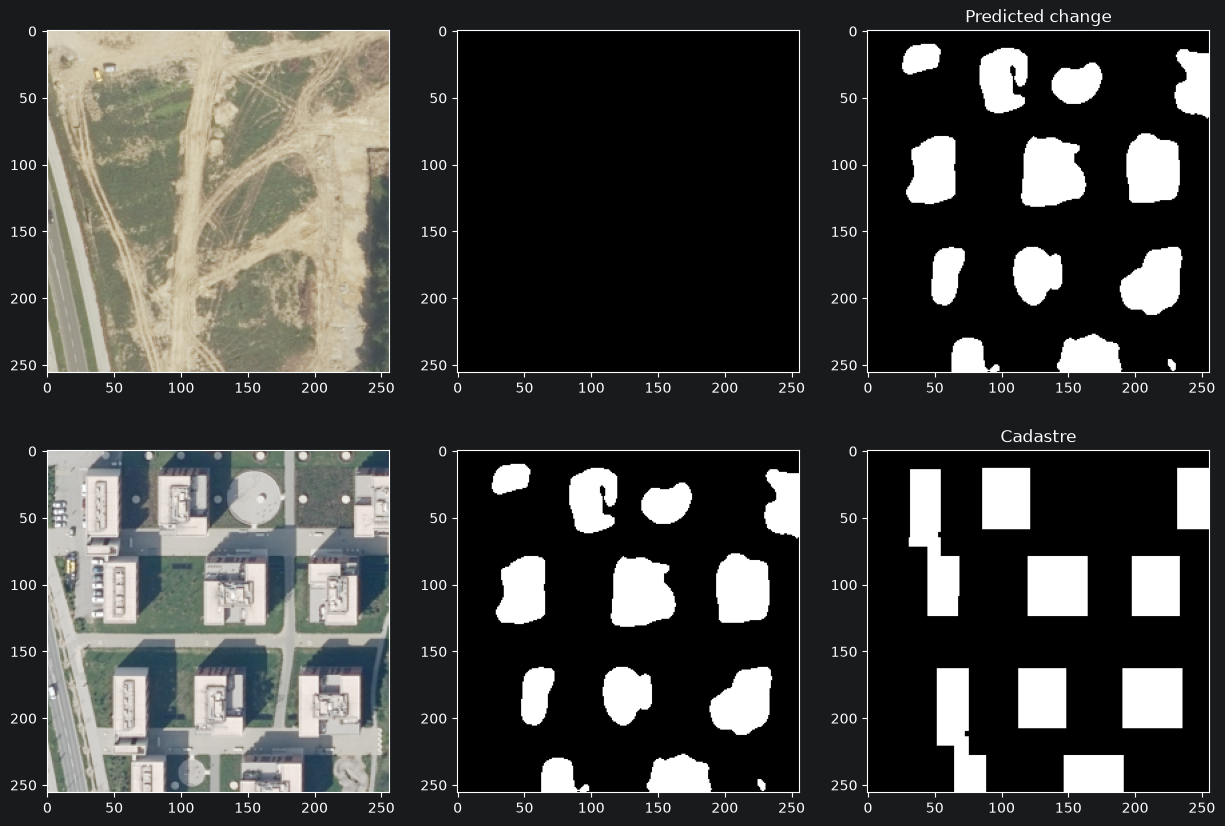

In [11]:
finetuned = SemanticSegmentation.load_from_checkpoint('../checkpoints/unet_buildings.ckpt')
finetuned = finetuned.to(DEVICE).eval()

show_change(finetuned, 458400, 100600)
score(finetuned)

# Why is this not the best approach?
Every mistake of the segmentation model becomes a change:

A small error in edge segmentation shows as change. Shadows, trees all of that causes potentially unwanted changes. Errors from both years add up, so in next notebook we will see how we can use both images to learn change detection directly.